# Estatística descritiva e consistência entre produtos

Série A masculina 2025, rodadas oficiais 1–38. Unidade coletiva; dados reais OpenFootball CC0.

In [1]:
import json
from pathlib import Path
import pandas as pd
root = Path.cwd()
document = json.loads((root / "data/analytics/collective.json").read_text(encoding="utf-8"))
facts = pd.DataFrame(document["team_matches"])
clubs = pd.DataFrame(document["club_totals"])
flamengo = facts[facts.club_id == "club:flamengo"]

In [2]:
from flamengo_pipeline.domain.collective import descriptive
print(descriptive(flamengo.goals_for.tolist()))
print(document["statistics"])
clubs[["points", "goals_for", "goals_against"]].corr()

{'n': 38, 'mean': 2.0526315789473686, 'median': 2.0, 'q1': 1.0, 'q3': 3.0, 'std_population': 1.746385265582848, 'variance_population': 3.049861495844875, 'min': 0.0, 'max': 8.0}
{'match_goals': {'n': 380, 'mean': 2.5236842105263158, 'median': 2.0, 'q1': 1.0, 'q3': 3.0, 'std_population': 1.5447592574362206, 'variance_population': 2.3862811634349033, 'min': 0.0, 'max': 8.0}, 'club_points': {'n': 20, 'mean': 52.05, 'median': 48.0, 'q1': 44.75, 'q3': 63.25, 'std_population': 14.34041491728883, 'variance_population': 205.64750000000004, 'min': 17.0, 'max': 79.0}, 'correlation_goals_points': 0.8927043236575675}


,points,goals_for,goals_against
points,1.000000,0.892704,-0.907554
goals_for,0.892704,1.000000,-0.722238
goals_against,-0.907554,-0.722238,1.000000


In [3]:
import subprocess
result = subprocess.run(["node", "scripts/validate-collective.mjs"], cwd=root, capture_output=True, text=True, check=True)
print(result.stdout)

{"checked_at":"2026-10-22T12:38:41.432Z","dataset_version":"0fcc4647256b2e1f58b50f1372b751aeb7e6aacb5b8cd747579dd7ab71303fbb","club_totals_compared":20,"accumulated_rows_compared":760,"result":"passed","postgres_validation":"npm run test:database uses isolated real PostgreSQL"}



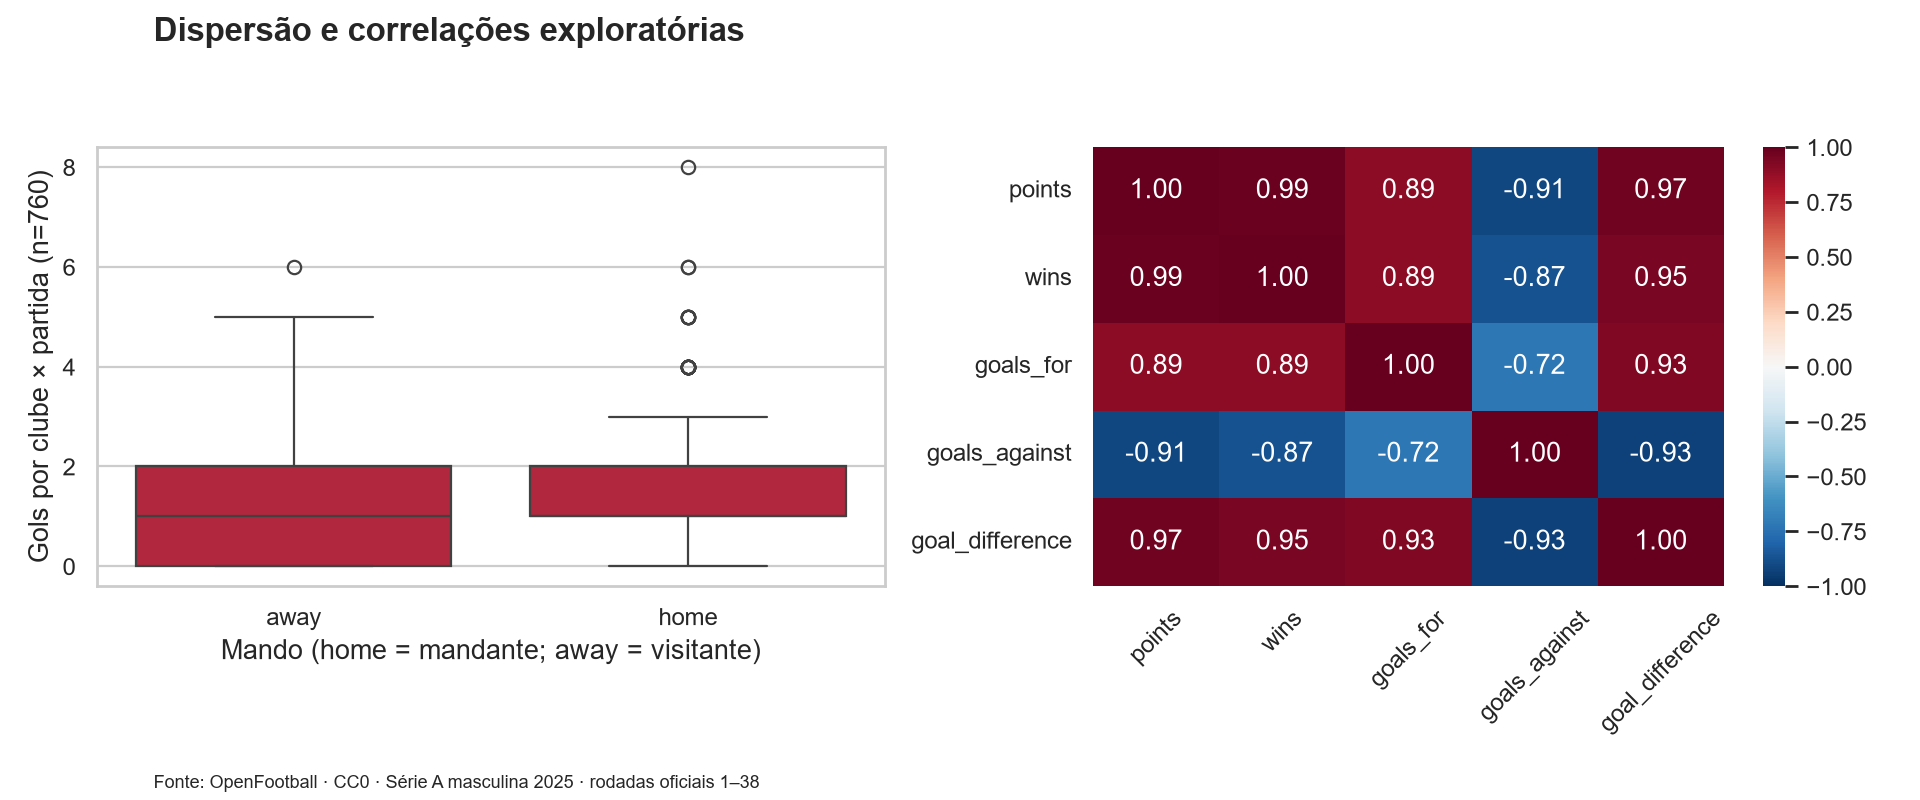

In [4]:
from IPython.display import Image, display
display(Image(filename=str(root / "reports/collective/06_estatistica.png")))

Quartis por interpolação linear, desvio e variância populacionais (ddof=0). Correlação gols pró × pontos = 0,8927 nos 20 clubes: exploratória, sem causalidade. SQL é comparado em cluster temporário por npm run test:database; DAX ainda depende de conferência no Desktop. 380 jogos demonstram conceitos Big Data, não processamento massivo.